In [203]:
import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import yaml
from matplotlib.colors import ListedColormap

with open("plotting_config.yaml") as fp:
    config = yaml.safe_load(fp)

<Axes: >

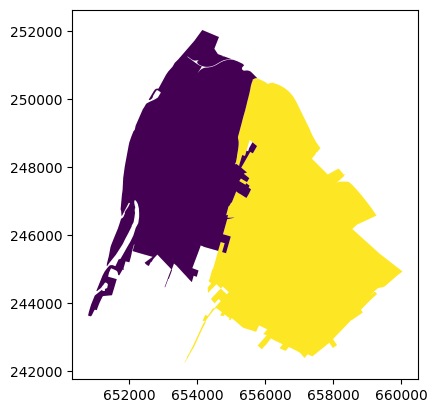

In [116]:
mc = gpd.read_file("../data/louvain_r2.5_merged.geojson")
mc.query("id.isin([18,24])").plot(column="id")
mc.query("id.isin([18,24])").plot(column="id")

In [127]:
area = mc.query("id.isin([18,24])").union_all()

In [199]:
with open("c27.txt", "r") as file:
    c27 = file.read()

colors = [f"#{i.split('#')[1]}" for i in c27.split("\n")[:-1]]

np.random.seed(11)
cmap = ListedColormap(np.random.permutation(colors))

In [28]:
hb = gpd.read_file("../data/house_blocks.geojson")
hb.set_crs(4326)
hb.to_crs(23700, inplace=True)
hb["geometry"] = hb.centroid
hb["lon"], hb["lat"] = round(hb["geometry"].x), round(hb["geometry"].y)
# hb.drop(["geometry", "area"], axis=1, inplace=True)
hb.drop(["area"], axis=1, inplace=True)
hb["id"] = hb["id"].apply(float)
hb["id"] = hb["id"].apply(str)

<Axes: >

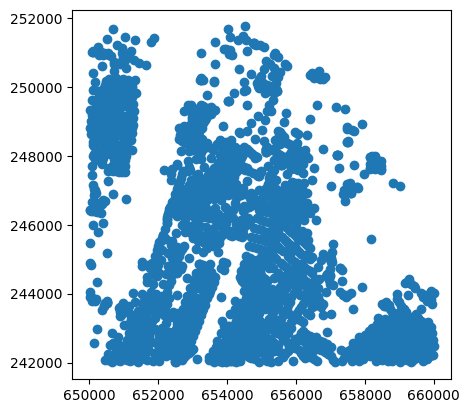

In [81]:
hb.query("lon.between(650000, 660000) & lat>242000").plot()

In [83]:
keep = hb.query("lon.between(650000, 660000) & lat>242000")["id"]
remove = hb[~hb["id"].isin(keep)]["id"]

In [84]:
comm = gpd.read_file("../data/2019-09-01_2020-02-29_resolution2.5.geojson")
comm["id"] = comm["id"].apply(float)
comm["id"] = comm["id"].apply(str)
comm_dict = comm[["id", "community"]].dropna().set_index("id").to_dict(orient="index")
comm.to_crs(23700, inplace=True)

In [104]:
keep_by_comm = comm.query("community.isin([14,15])")["id"].tolist()
remove_by_comm = hb[~hb["id"].isin(keep_by_comm)]["id"]

In [132]:
comm_filtered = (
    comm[comm["geometry"].intersects(area)].query("community.isin([14,15])").copy()
)

In [135]:
KEEP = comm[comm["geometry"].intersects(area)].query("community.isin([14,15])")["id"]
REMOVE = hb[~hb["id"].isin(KEEP)]["id"]

In [85]:
node_loc = hb.set_index("id").to_dict(orient="index")
pos = {k: [v["lon"], v["lat"]] for k, v in node_loc.items()}

In [136]:
g = nx.read_edgelist("../data/observed.edgelist.gz")

In [137]:
g.remove_nodes_from(REMOVE)

In [208]:
df = nx.to_pandas_edgelist(g)
df.head(3)

,source,target,weight
0,5247.0,5464.0,1
1,5247.0,6084.0,3
2,5247.0,5463.0,1


In [209]:
comm_lookup = comm[["id", "community"]].copy()

comm_lookup.columns = ["source", "source_community"]
df = df.merge(comm_lookup, on="source")
comm_lookup.columns = ["target", "target_community"]
df = df.merge(comm_lookup, on="target")

df["weight"] = df.apply(
    lambda x: x["weight"] * 2
    if x["source_community"] == x["target_community"]
    else x["weight"],
    axis=1,
)

In [222]:
df["ec"] = df.apply(
    lambda x: "#2d2d2d9d"
    if x["source_community"] == x["target_community"]
    else "#2d2d2d2d",
    axis=1,
)

In [223]:
degrees = {k: {"degree": v} for k, v in dict(g.degree).items()}

In [224]:
# for node position
nx.set_node_attributes(g, node_loc)
# for node size
nx.set_node_attributes(g, degrees)
# for node color
nx.set_node_attributes(g, comm_dict)

In [225]:
dl = list(dict(g.degree).values())
dl = [i / 50 for i in dl]

In [226]:
ew = [i / 100 for i in df["weight"]]
ns = [i / 5 for i in list(nx.get_node_attributes(g, "degree").values())]
nc = list(nx.get_node_attributes(g, "community").values())

In [227]:
max_degree = max(list(nx.get_node_attributes(g, "degree").values()))
nbw = [i / max_degree for i in list(nx.get_node_attributes(g, "degree").values())]

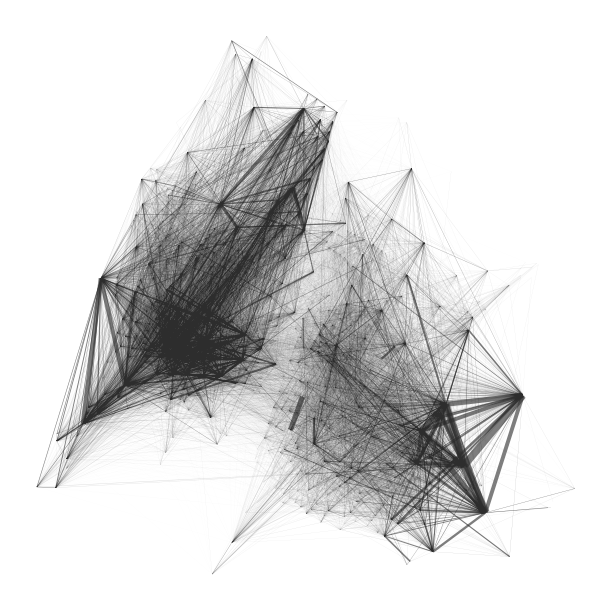

In [228]:
fig, ax = plt.subplots(figsize=(6, 6), layout="constrained")
nx.draw_networkx(
    g,
    pos=pos,
    with_labels=False,
    edgecolors="white",
    # linewidths=nbw,
    linewidths=0,
    node_size=ns,
    # node_color=nc,
    node_color="none",
    width=ew,
    # edge_color="#2d2d2d2d",
    edge_color=df["ec"],
    cmap=cmap,
    ax=ax,
)
ax.axis("off")
ax.margins(0)

In [229]:
for i in config["formats"]:
    fig.savefig(
        f"../figures/community.{i}",
        dpi=300,
        facecolor="white",
        # bbox_inches="tight",
        metadata=config["metadata"] if i != "svg" else None,
    )